# 11 — EfficientNet-B3 training

**Purpose:** Train a two-logit Normal/Blast classifier with a CUDA smoke test and head/fine phases.

**Required inputs:** Saved subject splits; CUDA-enabled PyTorch; ImageNet weights download or cache.

**Saved outputs:** Timestamped outputs/classifier/runs/<run>/ checkpoints, logs, CSV and plots.

## 1. Load central configuration

Set `cnmc_root` once in ignored `config.local.yaml`. Source images are never moved or changed.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "classifier_config.py").is_file():
        sys.path.insert(0, str(candidate)); break
from src.classifier_config import classifier_config, classifier_output
cfg = classifier_config()
out = classifier_output(cfg)
print("Project:", cfg["root"])
print("Config:", cfg["config_path"])
print("C-NMC source:", cfg["cnmc_root"])

Project: D:\CellCancer\leukemia-yolo
Config: D:\CellCancer\leukemia-yolo\config.local.yaml
C-NMC source: D:\Datasets\C-NMC_Leukemia


## A. GPU and data readiness

GPU training never falls back silently to CPU.

In [2]:
from src.classifier_training import require_classifier_cuda, class_weights
from src.cnmc_splits import create_or_load_splits, validate_splits
import torch
device = require_classifier_cuda()
splits, split_info = create_or_load_splits(cfg)
display(__import__("pandas").DataFrame(validate_splits(splits)).T)
print("GPU:", torch.cuda.get_device_name(0), "free GiB:", round(torch.cuda.mem_get_info(0)[0]/2**30, 2))
print("Image size:", cfg["classifier_image_size"], "batch:", cfg["classifier_batch_size"])
print("Class weights [Normal, Blast]:", class_weights(splits["train"], device).tolist())

,images,subjects,normal,blast
train,4667,30,1600,3067
val,1185,8,270,915
test,3553,31,1096,2457


GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU free GiB: 3.21
Image size: 224 batch: 8
Class weights [Normal, Blast]: [1.458437442779541, 0.7608411908149719]


## B. Model architecture

Torchvision's DEFAULT ImageNet B3 weights; final head returns exactly two logits.

In [3]:
from src.classifier_model import build_model, set_trainable, metadata
model = build_model(pretrained=True).to(device)
set_trainable(model, "head")
print(model.classifier)
print(metadata(cfg["classifier_image_size"]))

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to C:\Users\majid/.cache\torch\hub\checkpoints\efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:31<00:00, 1.58MB/s]


Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1536, out_features=2, bias=True)
)
{'architecture': 'torchvision.efficientnet_b3', 'weights': 'EfficientNet_B3_Weights.IMAGENET1K_V1', 'class_mapping': {'0': 'Normal (HEM)', '1': 'Leukemic Blast (ALL)'}, 'image_size': 224, 'normalization': {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}, 'preprocessing_version': 'cnmc_rgb_square_v1', 'decision_threshold': 0.5, 'positive_class': 1}


## C. Preview the deterministic validation batch

At 224 pixels this differs from B3's original 300-pixel center-crop recipe; the choice is recorded.

In [4]:
from src.classifier_transforms import CNMCDataset
from torch.utils.data import DataLoader
batch = next(iter(DataLoader(CNMCDataset(splits["val"], cfg["classifier_image_size"]), batch_size=2)))
print("Batch RGB tensor:", batch[0].shape, "labels:", batch[1].tolist())
assert batch[0].shape[1:] == (3, cfg["classifier_image_size"], cfg["classifier_image_size"])

Batch RGB tensor: torch.Size([2, 3, 224, 224]) labels: [1, 1]


## D. One-batch forward and backward check

Only the new head receives gradients in phase A.

In [5]:
from torch import nn
model.train(); model.features.eval()
x, y = batch[0].to(device), batch[1].to(device)
logits = model(x); assert logits.shape == (2, 2)
loss = nn.CrossEntropyLoss()(logits, y); loss.backward()
assert model.classifier[-1].weight.grad is not None
print("PASS — forward/backward; loss:", float(loss.detach()))
model.zero_grad(set_to_none=True); del x, y, logits, loss

PASS — forward/backward; loss: 0.8481560349464417


## E. Launch one-epoch smoke test

The guarded child script handles Windows workers. Logs stream live and are saved in its run folder.

In [6]:
import subprocess, sys
def stream_command(arguments):
    command = [sys.executable, "-u", *map(str, arguments)]
    process = subprocess.Popen(command, cwd=cfg["root"], stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, encoding="utf-8", errors="replace", bufsize=1)
    try:
        for line in process.stdout: print(line, end="", flush=True)
    except KeyboardInterrupt:
        process.terminate(); process.wait()
        raise RuntimeError("Training stopped. Resume from the run's last_checkpoint.pth")
    code = process.wait()
    if code: raise RuntimeError(f"Child process exited {code}; inspect training_log.txt")
stream_command([cfg["root"] / "scripts" / "train_classifier.py", "--mode", "smoke"])

TRAIN-only class weights [Normal, Blast]: [1.458437442779541, 0.7608411908149719]
{"phase": "head", "epoch": 1, "train_loss": 0.634925127029419, "val_loss": 0.9665832817554474, "val_accuracy": 0.0, "val_macro_f1": 0.0, "val_blast_sensitivity": 0.0, "elapsed_seconds": 38.75, "batch_size": 8, "peak_vram_bytes": 128725504}
Classifier run: D:\CellCancer\leukemia-yolo\outputs\classifier\runs\smoke_20261013T110339Z_f5878c5a


## F. Verify smoke artifacts

Full training is gated on a successful CUDA checkpoint.

In [7]:
from src.classifier_model import load_checkpoint
smokes = sorted((out / "runs").glob("smoke_*/best_model.pth"))
assert smokes, "No successful CUDA smoke checkpoint"
smoke_model, smoke_info, _ = load_checkpoint(smokes[-1], device)
print("PASS — loaded smoke checkpoint:", smokes[-1])
del smoke_model

PASS — loaded smoke checkpoint: D:\CellCancer\leukemia-yolo\outputs\classifier\runs\smoke_20261013T110339Z_f5878c5a\best_model.pth


## G. Run full two-phase training

Separate timestamped run. Stop with Interrupt; resume with --resume last_checkpoint.pth.

In [8]:
stream_command([cfg["root"] / "scripts" / "train_classifier.py", "--mode", "full"])
print("PASS — child process completed")

TRAIN-only class weights [Normal, Blast]: [1.458437442779541, 0.7608411908149719]
{"phase": "head", "epoch": 1, "train_loss": 0.48554806458840205, "val_loss": 0.46422549395621576, "val_accuracy": 0.7974683544303798, "val_macro_f1": 0.7507571933366987, "val_blast_sensitivity": 0.7967213114754098, "elapsed_seconds": 68.17, "batch_size": 8, "peak_vram_bytes": 128725504}
{"phase": "head", "epoch": 2, "train_loss": 0.44571760768728946, "val_loss": 0.41885427493083327, "val_accuracy": 0.8320675105485232, "val_macro_f1": 0.7846613380282333, "val_blast_sensitivity": 0.8426229508196721, "elapsed_seconds": 96.78, "batch_size": 8, "peak_vram_bytes": 128725504}
{"phase": "head", "epoch": 3, "train_loss": 0.4260747535647124, "val_loss": 0.3713364554231177, "val_accuracy": 0.8717299578059071, "val_macro_f1": 0.818673088074222, "val_blast_sensitivity": 0.9147540983606557, "elapsed_seconds": 125.92, "batch_size": 8, "peak_vram_bytes": 128725504}
{"phase": "head", "epoch": 4, "train_loss": 0.4254276890

## H. Review outputs and GPU memory

History is written after each complete epoch; incomplete CSV lines are ignored by a fresh read after exit.

In [9]:
import pandas as pd
from src.classifier_config import latest_classifier_run
run = latest_classifier_run(cfg)
history = pd.read_csv(run / "training_history.csv")
display(history.tail(10))
print("Child-process peak allocated VRAM GiB:", round(history.peak_vram_bytes.max()/2**30, 2))
print("Training log:", run / "training_log.txt")

,phase,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_blast_sensitivity,elapsed_seconds,batch_size,peak_vram_bytes
0,head,1,0.485548,0.464225,0.797468,0.750757,0.796721,68.17,8,128725504
1,head,2,0.445718,0.418854,0.832068,0.784661,0.842623,96.78,8,128725504
2,head,3,0.426075,0.371336,0.871730,0.818673,0.914754,125.92,8,128725504
3,head,4,0.425428,0.444021,0.820253,0.774019,0.824044,154.42,8,128725504
4,fine,1,0.500747,0.537188,0.788186,0.743194,0.781421,223.81,8,177885696
5,fine,2,0.417702,0.384535,0.867511,0.814844,0.907104,255.72,8,177885696
6,fine,3,0.368825,0.429866,0.859072,0.812201,0.879781,293.45,8,177885696


Child-process peak allocated VRAM GiB: 0.17
Training log: D:\CellCancer\leukemia-yolo\outputs\classifier\runs\efficientnet_b3_20261013T110511Z_67988092\training_log.txt


## I. Inspect curves and selected checkpoint

The best model is selected by validation macro-F1, never test metrics.

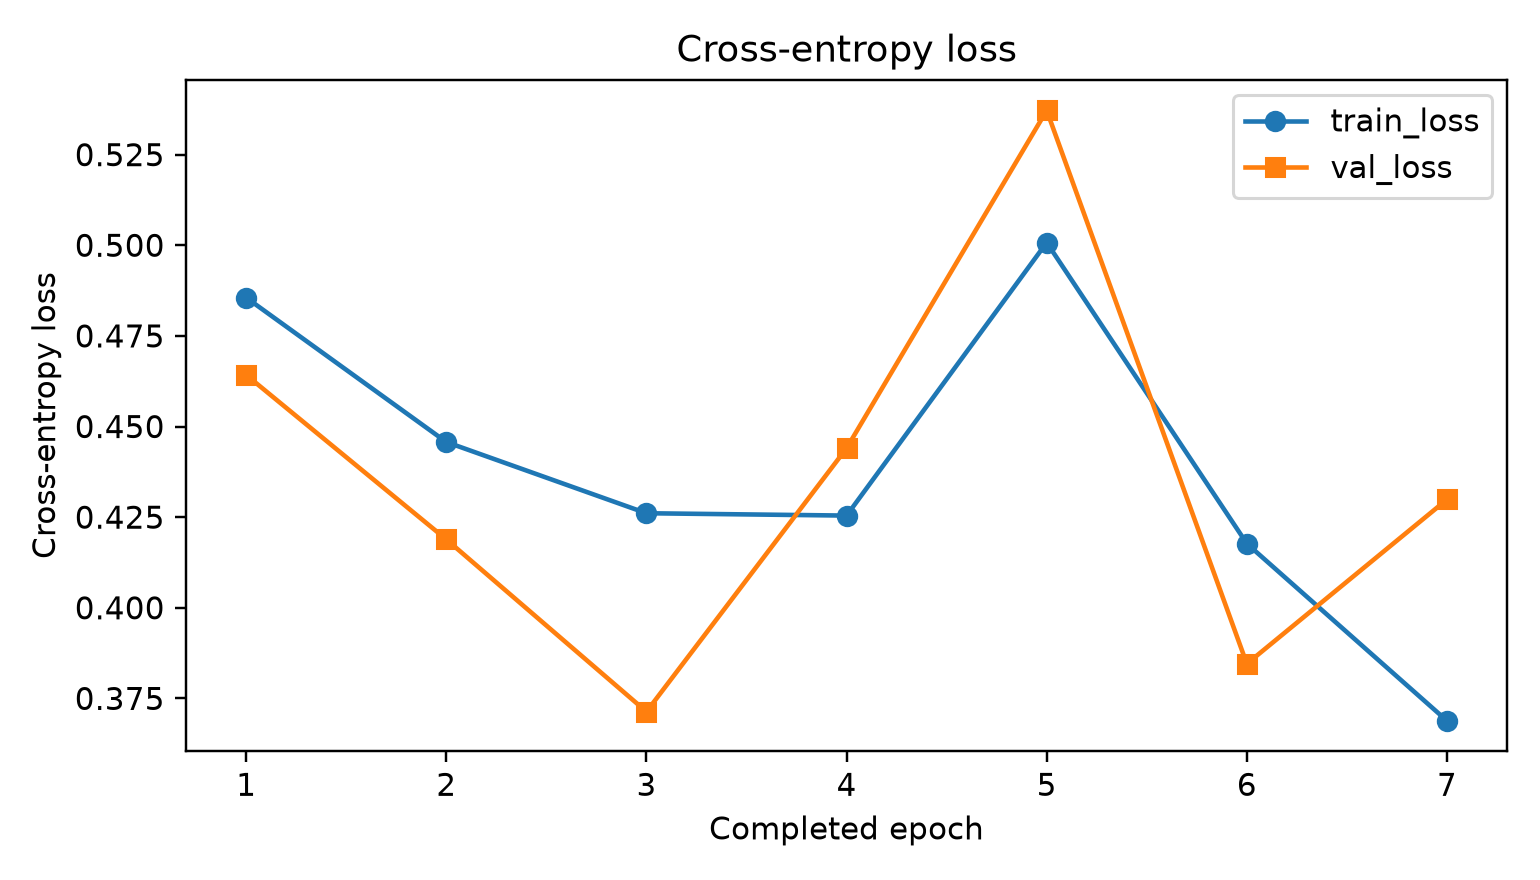

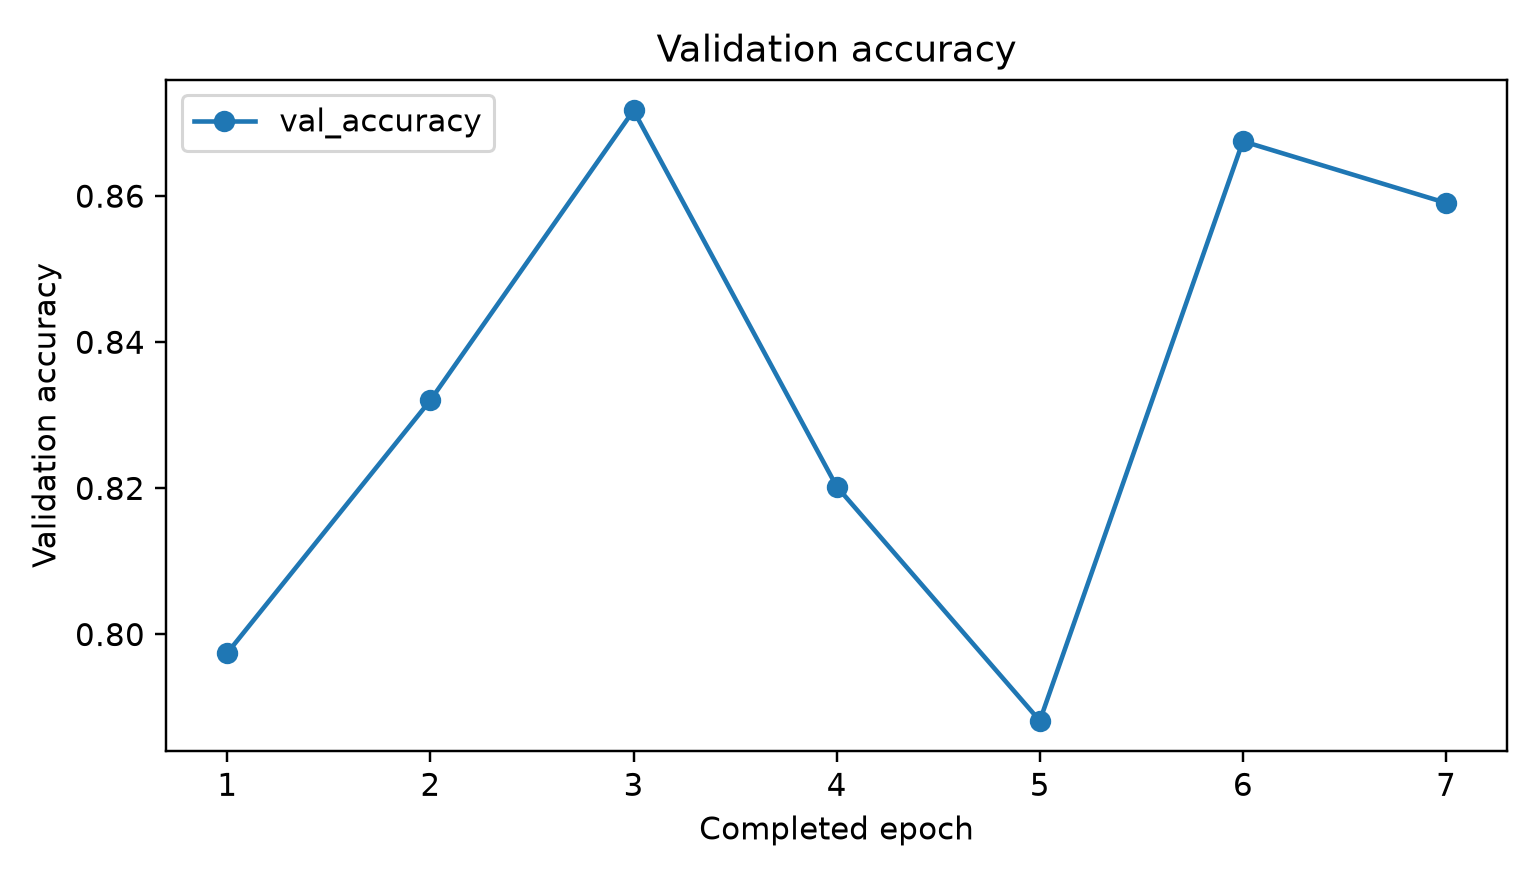

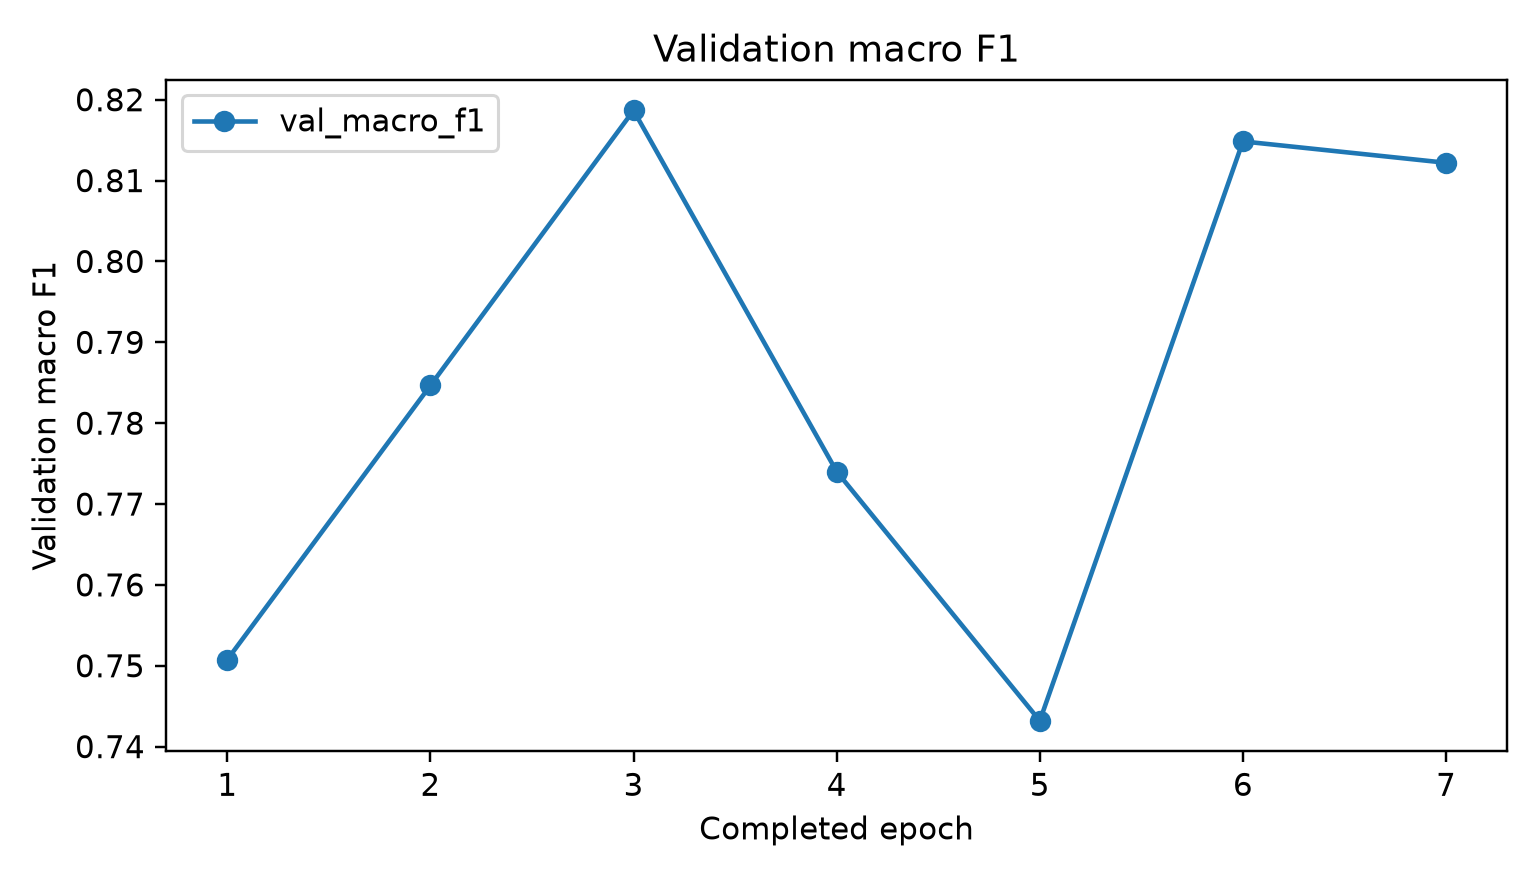

PASS — best checkpoint: D:\CellCancer\leukemia-yolo\outputs\classifier\runs\efficientnet_b3_20261013T110511Z_67988092\best_model.pth
Validation macro-F1: 0.818673088074222 class mapping: {'0': 'Normal (HEM)', '1': 'Leukemic Blast (ALL)'}


In [10]:
from IPython.display import Image as DisplayImage, display
for filename in ("loss_curve.png", "accuracy_curve.png", "f1_curve.png"):
    display(DisplayImage(filename=str(run / filename)))
best_model, best_info, selected = load_checkpoint(run / "best_model.pth", device)
print("PASS — best checkpoint:", run / "best_model.pth")
print("Validation macro-F1:", selected["validation_macro_f1"], "class mapping:", best_info["class_mapping"])

## Next

Open **12_EfficientNet_B3_Evaluation.ipynb**. Test fold_2 is used only after model selection.